# Plot Backazimuth Results

This notebook plots the backazimuth results from `04_XROMY_event_analysis.py`.


## Notebook Overview
This notebook summarizes and visualizes backazimuth estimation performance across processed events.

**Main workflow**
- Load backazimuth result tables from `output/`.
- Compare estimated vs theoretical backazimuth.
- Analyze residuals, uncertainty, and method dependence.
- Build compact summary plots.
- Save figure outputs for reporting.

## Imports

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

from scipy import stats
from obspy.geodetics import gps2dist_azimuth, kilometers2degrees


## Configuration

In [2]:
# Path to backazimuth results
path_to_data = "./output/results_backazimuth.csv"

# Output directory for figures
output_dir = "./output/figures/backazimuth"
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

7


In [3]:
# Load backazimuth results
df_baz = pd.read_csv(path_to_data)

print(f"Loaded {len(df_baz)} rows")
print(f"\nColumns: {list(df_baz.columns)}")
print(f"\nWave types: {df_baz['wave_type'].unique()}")
print(f"\nCC methods: {df_baz['cc_method'].unique()}")
print(f"\nEvents: {df_baz['event_date'].unique()}")
df_baz.head()

Loaded 114 rows

Columns: ['event_date', 'origin_time', 'magnitude', 'distance_km', 'wave_type', 'cc_method', 'n_samples', 'backazimuth_estimate', 'backazimuth_uncertainty', 'backazimuth_theoretical', 'backazimuth_residual', 'cc_threshold']

Wave types: ['love' 'rayleigh' 'tangent']

CC methods: ['mid' 'max']

Events: [20190514 20230908 20230912 20231202 20240314 20240322 20240323 20240414
 20240422 20240815 20240915 20241023 20250513 20250602 20251206 20251212
 20251227 20260107 20260420]


,event_date,origin_time,magnitude,distance_km,wave_type,cc_method,n_samples,backazimuth_estimate,backazimuth_uncertainty,backazimuth_theoretical,backazimuth_residual,cc_threshold
0,20190514,2019-05-14T12:58:25.939000Z,7.6,13894.14,love,mid,76,52.0,17.0,49.29,2.7,0.8
1,20190514,2019-05-14T12:58:25.939000Z,7.6,13894.14,rayleigh,mid,76,41.0,18.0,49.29,-8.3,0.8
2,20190514,2019-05-14T12:58:25.939000Z,7.6,13894.14,tangent,mid,72,43.0,15.0,49.29,-6.3,0.8
3,20190514,2019-05-14T12:58:25.939000Z,7.6,13894.14,love,max,97,56.0,10.0,49.29,6.7,0.8
4,20190514,2019-05-14T12:58:25.939000Z,7.6,13894.14,rayleigh,max,80,32.0,26.0,49.29,-17.3,0.8


## Backazimuth Comparison by Wave Type

Compare estimated backazimuth (with uncertainty) versus theoretical value for each wave type.

Saved: ./output/figures/backazimuth_comparison_love.png


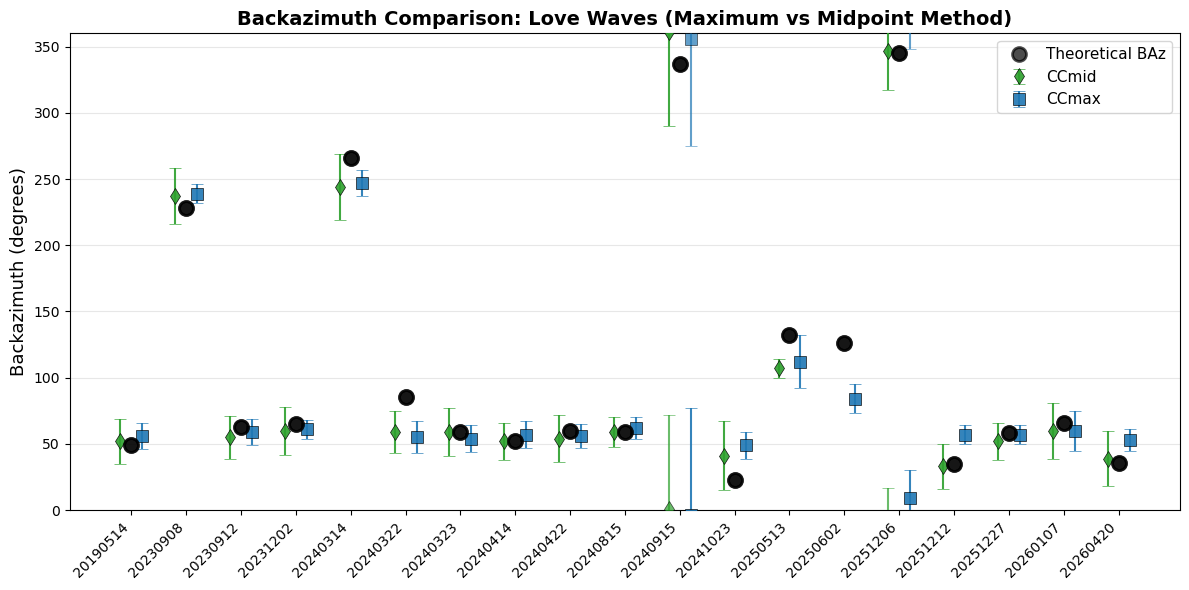

Saved: ./output/figures/backazimuth_comparison_rayleigh.png


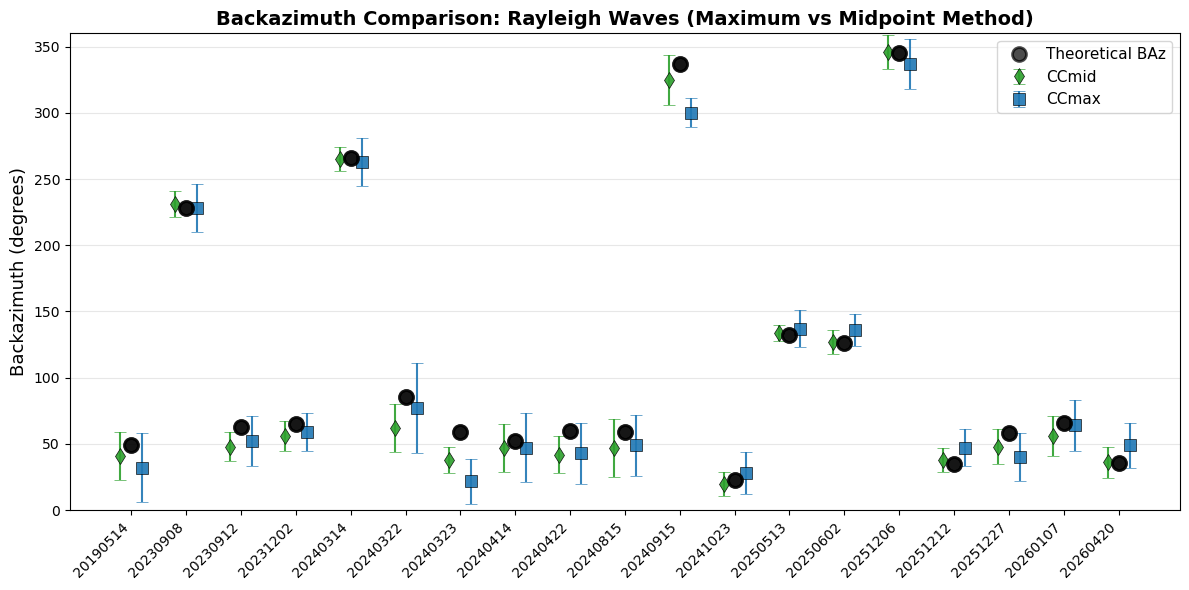

Saved: ./output/figures/backazimuth_comparison_tangent.png


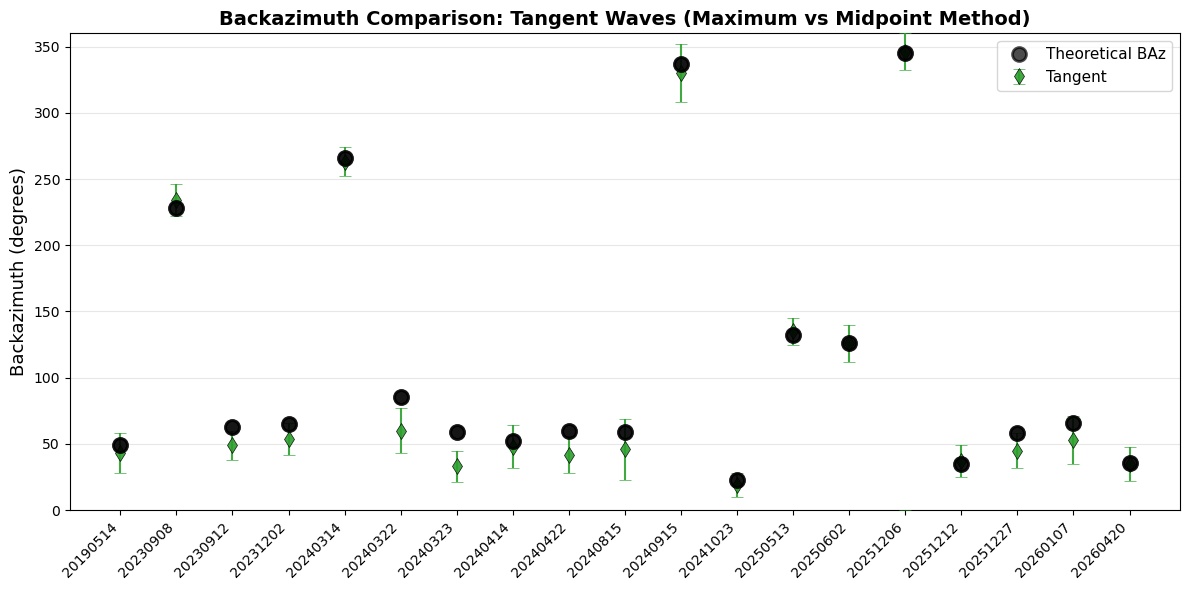

In [4]:
# Function to plot backazimuth comparison for a specific wave type
def plot_backazimuth_comparison(df, wave_type, ax=None):
    """Plot backazimuth comparison for a specific wave type."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 6))
    else:
        fig = ax.figure
    
    # Filter data for this wave type
    df_wave = df[df['wave_type'] == wave_type].copy()
    
    # Get unique events
    events = df_wave['event_date'].unique()
    x_base = np.arange(len(events))
    width = 0.2
    
    # Get theoretical values (should be same for all methods for same event)
    theoretical = []
    for event in events:
        theo_val = df_wave[df_wave['event_date'] == event]['backazimuth_theoretical'].iloc[0]
        theoretical.append(theo_val)
    theoretical = np.array(theoretical)
    
    # Plot theoretical values
    ax.errorbar(x_base, theoretical, fmt='o', color='black', markersize=10, 
                label='Theoretical BAz', linewidth=2.5, zorder=10, markeredgewidth=2, alpha=0.7)
    ax.errorbar(x_base, theoretical % 360, fmt='o', color='black', markersize=10, 
                linewidth=2.5, zorder=10, markeredgewidth=2, alpha=0.7)
    
    # Determine which methods to plot
    # For tangent, only plot mid; for others, plot both mid and max
    methods_to_plot = ['mid'] if wave_type == 'tangent' else ['mid', 'max']
    
    # Labels for methods
    method_labels = {
        'mid': 'CCmid' if wave_type != 'tangent' else 'Tangent',
        'max': 'CCmax'
    }
    
    # Plot mid method
    if 'mid' in methods_to_plot:
        df_mid = df_wave[df_wave['cc_method'] == 'mid'].copy()
        if len(df_mid) > 0:
            # Match events to x positions
            x_mid = []
            est_mid = []
            unc_mid = []
            for i, event in enumerate(events):
                event_data = df_mid[df_mid['event_date'] == event]
                if len(event_data) > 0:
                    x_mid.append(i - width if 'max' in methods_to_plot else i)
                    est_mid.append(event_data['backazimuth_estimate'].iloc[0])
                    unc_mid.append(event_data['backazimuth_uncertainty'].iloc[0])
            
            if len(x_mid) > 0:
                x_mid = np.array(x_mid)
                est_mid = np.array(est_mid)
                unc_mid = np.array(unc_mid)
                
                label = method_labels['mid']
                ax.errorbar(x_mid, est_mid, yerr=unc_mid, fmt='d', color='tab:green', 
                            markersize=8, capsize=4, capthick=1.5, alpha=0.9,
                            label=label, linewidth=1.5, zorder=5, markeredgecolor='k', markeredgewidth=0.5)
                ax.errorbar(x_mid, est_mid + 360, yerr=unc_mid, fmt='d', color='tab:green', 
                            markersize=8, capsize=4, capthick=1.5, alpha=0.7,
                            linewidth=1.5, zorder=5, markeredgecolor='k', markeredgewidth=0.5)
                ax.errorbar(x_mid, est_mid - 360, yerr=unc_mid, fmt='d', color='tab:green', 
                            markersize=8, capsize=4, capthick=1.5, alpha=0.7,
                            linewidth=1.5, zorder=5, markeredgecolor='k', markeredgewidth=0.5)
    
    # Plot max method
    if 'max' in methods_to_plot:
        df_max = df_wave[df_wave['cc_method'] == 'max'].copy()
        if len(df_max) > 0:
            # Match events to x positions
            x_max = []
            est_max = []
            unc_max = []
            for i, event in enumerate(events):
                event_data = df_max[df_max['event_date'] == event]
                if len(event_data) > 0:
                    x_max.append(i + width)
                    est_max.append(event_data['backazimuth_estimate'].iloc[0])
                    unc_max.append(event_data['backazimuth_uncertainty'].iloc[0])
            
            if len(x_max) > 0:
                x_max = np.array(x_max)
                est_max = np.array(est_max)
                unc_max = np.array(unc_max)
                
                label = method_labels['max']
                ax.errorbar(x_max, est_max, yerr=unc_max, fmt='s', color='tab:blue', 
                            markersize=8, capsize=4, capthick=1.5, alpha=0.9,
                            label=label, linewidth=1.5, zorder=5, markeredgecolor='k', markeredgewidth=0.5)
                ax.errorbar(x_max, est_max + 360, yerr=unc_max, fmt='s', color='tab:blue', 
                            markersize=8, capsize=4, capthick=1.5, alpha=0.7,
                            linewidth=1.5, zorder=5, markeredgecolor='k', markeredgewidth=0.5)
                ax.errorbar(x_max, est_max - 360, yerr=unc_max, fmt='s', color='tab:blue', 
                            markersize=8, capsize=4, capthick=1.5, alpha=0.7,
                            linewidth=1.5, zorder=5, markeredgecolor='k', markeredgewidth=0.5)
    
    ax.set_ylabel('Backazimuth (degrees)', fontsize=13)
    ax.set_title(f'Backazimuth Comparison: {wave_type.capitalize()} Waves (Maximum vs Midpoint Method)', 
                 fontsize=14, fontweight='bold')
    ax.set_xticks(x_base)
    ax.set_xticklabels(events, rotation=45, ha='right')
    ax.set_ylim(0, 360)
    ax.legend(fontsize=11, loc='best')
    ax.grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    return fig, ax

# Plot for each wave type
wave_types = ['love', 'rayleigh', 'tangent']
for wave_type in wave_types:
    if wave_type in df_baz['wave_type'].values:
        fig, ax = plot_backazimuth_comparison(df_baz, wave_type)
        output_file = os.path.join(output_dir, f'backazimuth_comparison_{wave_type}.png')
        fig.savefig(output_file, bbox_inches='tight', dpi=150)
        print(f"Saved: {output_file}")
        plt.show()

## Combined Backazimuth Comparison

Compare all wave types (Love, Rayleigh, Tangent) and methods (mid, max) versus theoretical values.

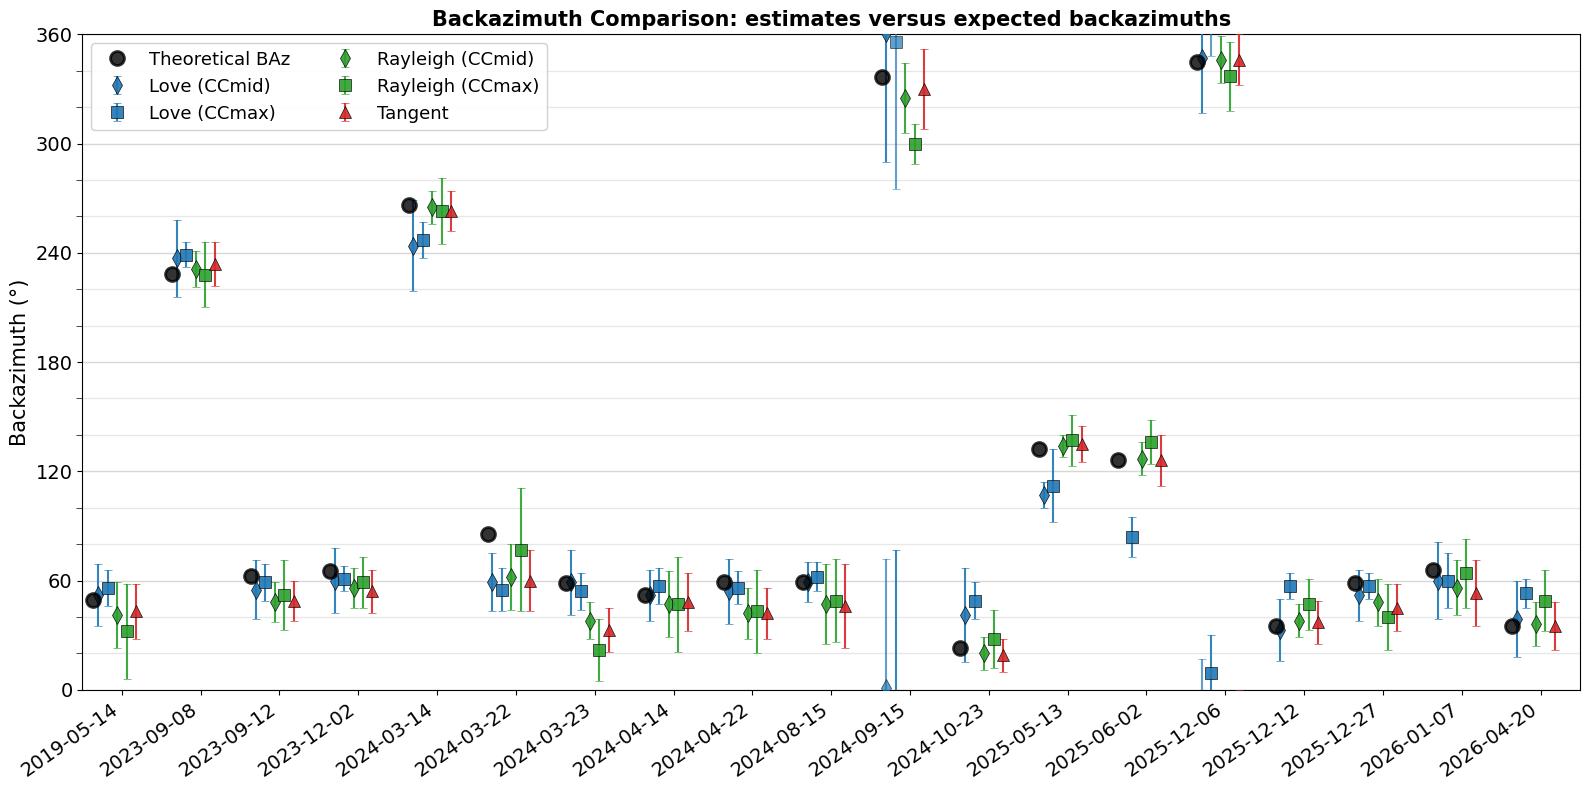

Saved: ./output/figures/backazimuth_comparison_all.png


In [5]:
# Combined plot: All wave types and methods vs theoretical
fig, ax = plt.subplots(figsize=(16, 8))

# Get unique events
events = df_baz['event_date'].unique()
x_base = np.arange(len(events))
width = 0.12

# Colors and markers for different wave types and methods
colors = {
    ('love', 'mid'): 'tab:blue',
    ('love', 'max'): 'tab:blue',
    ('rayleigh', 'mid'): 'tab:green',
    ('rayleigh', 'max'): 'tab:green',
    ('tangent', 'mid'): 'tab:red',
    ('tangent', 'max'): 'tab:red',
}

markers = {
    ('love', 'mid'): 'd',
    ('love', 'max'): 's',
    ('rayleigh', 'mid'): 'd',
    ('rayleigh', 'max'): 's',
    ('tangent', 'mid'): '^',
    ('tangent', 'max'): 'v',
}

labels = {
    ('love', 'mid'): 'Love (CCmid)',
    ('love', 'max'): 'Love (CCmax)',
    ('rayleigh', 'mid'): 'Rayleigh (CCmid)',
    ('rayleigh', 'max'): 'Rayleigh (CCmax)',
    ('tangent', 'mid'): 'Tangent',
    ('tangent', 'max'): 'Tangent Max',  # Not used but kept for consistency
}

# Get theoretical values
theoretical = []
for event in events:
    theo_val = df_baz[df_baz['event_date'] == event]['backazimuth_theoretical'].iloc[0]
    theoretical.append(theo_val)
theoretical = np.array(theoretical)

# Plot theoretical values
x_theoretical = x_base - width * 3
ax.errorbar(x_theoretical, theoretical, fmt='o', color='black', markersize=10, 
            label='Theoretical BAz', linewidth=2.5, zorder=10, markeredgewidth=2, alpha=0.8)
# ax.errorbar(x_theoretical, theoretical % 360, fmt='o', color='black', markersize=10, 
#             linewidth=2.5, zorder=10, markeredgewidth=2, alpha=0.7)

# Plot each combination
offset = -2.5
for wave_type in ['love', 'rayleigh', 'tangent']:
    # For tangent, only plot mid method
    methods_to_plot = ['mid', 'max'] if wave_type != 'tangent' else ['mid']
    
    for cc_method in methods_to_plot:
        df_subset = df_baz[(df_baz['wave_type'] == wave_type) & 
                           (df_baz['cc_method'] == cc_method)].copy()
        
        if len(df_subset) > 0:
            x_pos = []
            est_vals = []
            unc_vals = []
            
            for i, event in enumerate(events):
                event_data = df_subset[df_subset['event_date'] == event]
                if len(event_data) > 0:
                    x_pos.append(i + offset * width)
                    est_vals.append(event_data['backazimuth_estimate'].iloc[0])
                    unc_vals.append(event_data['backazimuth_uncertainty'].iloc[0])
            
            if len(x_pos) > 0:
                x_pos = np.array(x_pos)
                est_vals = np.array(est_vals)
                unc_vals = np.array(unc_vals)
                
                key = (wave_type, cc_method)
                ax.errorbar(x_pos, est_vals, yerr=unc_vals, 
                           fmt=markers[key], color=colors[key], 
                           markersize=9, capsize=3, capthick=1.5, alpha=0.9,
                           label=labels[key], linewidth=1.5, zorder=5, 
                           markeredgecolor='k', markeredgewidth=0.5)
                ax.errorbar(x_pos, est_vals + 360, yerr=unc_vals, 
                           fmt=markers[key], color=colors[key], 
                           markersize=9, capsize=3, capthick=1.5, alpha=0.7,
                           linewidth=1.5, zorder=5, markeredgecolor='k', markeredgewidth=0.5)
                ax.errorbar(x_pos, est_vals - 360, yerr=unc_vals, 
                           fmt=markers[key], color=colors[key], 
                           markersize=9, capsize=3, capthick=1.5, alpha=0.7,
                           linewidth=1.5, zorder=5, markeredgecolor='k', markeredgewidth=0.5)
        
        offset += 1

# Set major ticks every 60 degrees
ax.set_yticks(np.arange(0, 420, 60))
# Set minor ticks every 20 degrees
ax.set_yticks(np.arange(0, 420, 20), minor=True)

ax.tick_params(axis='both', which='major', labelsize=14)
ax.tick_params(axis='y', which='minor', length=4, width=0.5)

ax.set_ylabel('Backazimuth (°)', fontsize=15)
ax.set_title('Backazimuth Comparison: estimates versus expected backazimuths', 
             fontsize=15, fontweight='bold')
ax.set_xticks(x_base)
xlables = [str(l)[:4]+"-"+str(l)[4:6]+"-"+str(l)[6:] for l in events]
ax.set_xticklabels(xlables, rotation=35, ha='right', fontsize=14)
ax.set_ylim(0, 360)
ax.legend(fontsize=13, loc='best', ncol=2, framealpha=0.9)
ax.set_xlim(-0.5, len(events)-0.5)

# Add gridlines for both major and minor ticks
ax.grid(which='major', alpha=0.5, axis='y', linestyle='-', linewidth=1)
ax.grid(which='minor', alpha=0.3, axis='y', linestyle='-', linewidth=0.9)

plt.tight_layout()
plt.show()

output_file = os.path.join(output_dir, 'backazimuth_comparison_all.png')
fig.savefig(output_file, bbox_inches='tight', dpi=150)
print(f"Saved: {output_file}")

## Histogram of Backazimuth Deviations

Distribution of deviations from theoretical backazimuth for all methods.

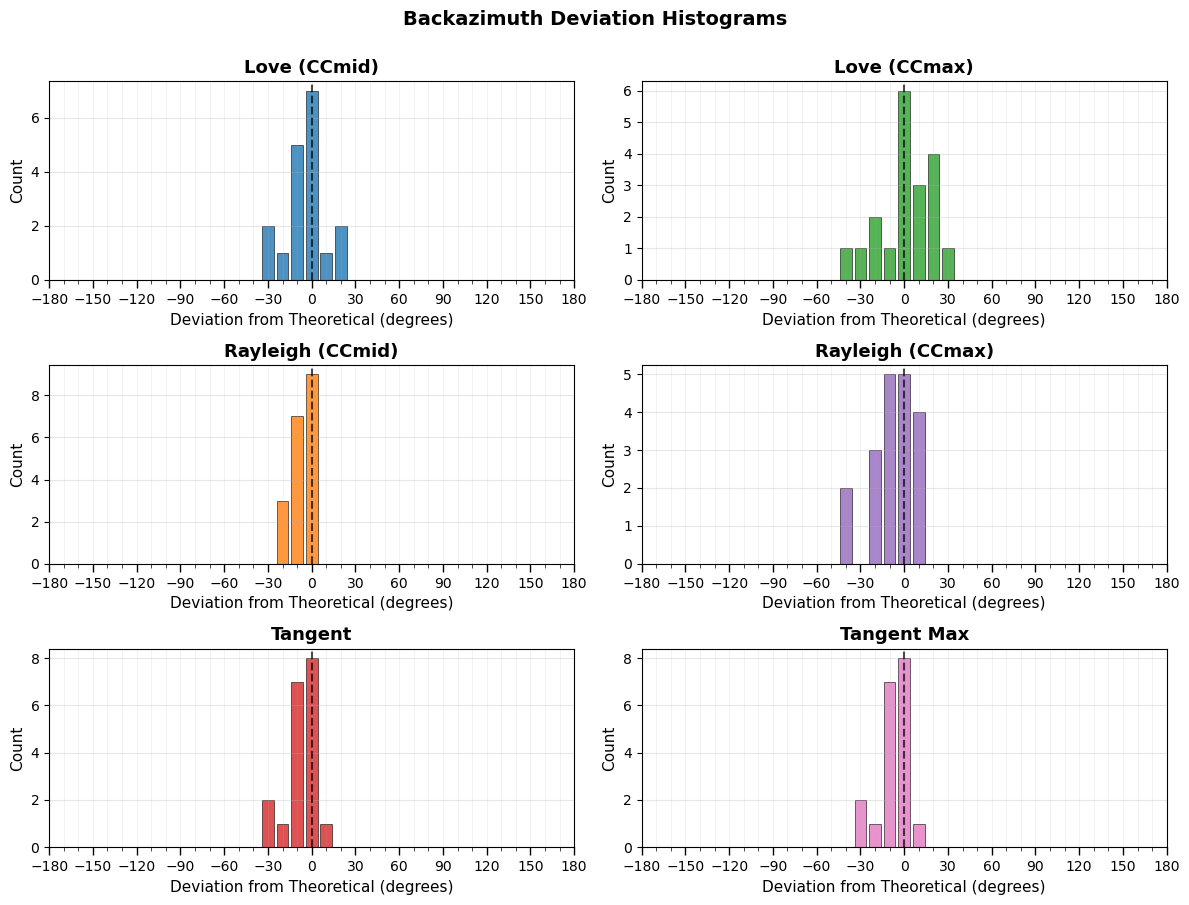

Saved: ./output/figures/backazimuth_deviation_histogram.png

Statistics:
  Love Mid:
    Mean: -2.57° ± 12.73°
    Median: -1.11°
    Min: -26.48°, Max: 24.37°
  Love Max:
    Mean: -0.03° ± 18.09°
    Median: -1.53°
    Min: -42.38°, Max: 26.17°
  Rayleigh Mid:
    Mean: -7.19° ± 7.98°
    Median: -8.29°
    Min: -23.48°, Max: 3.09°
  Rayleigh Max:
    Mean: -7.03° ± 13.71°
    Median: -6.16°
    Min: -36.74°, Max: 13.76°
  Tangent Mid:
    Mean: -7.66° ± 8.87°
    Median: -6.29°
    Min: -25.74°, Max: 5.60°
  Tangent Max:
    Mean: -7.66° ± 8.87°
    Median: -6.29°
    Min: -25.74°, Max: 5.60°


In [6]:
# Function to calculate circular deviation (wrapped to [-180, 180])
def circular_deviation(estimated, theoretical):
    """Calculate deviation between estimated and theoretical, wrapped to [-180, 180] degrees."""
    diff = estimated - theoretical
    # Wrap to [-180, 180]
    diff = np.where(diff > 180, diff - 360, diff)
    diff = np.where(diff < -180, diff + 360, diff)
    return diff

# Calculate deviations for all methods
deviations = {}

for wave_type in ['love', 'rayleigh', 'tangent']:
    for cc_method in ['mid', 'max']:
        df_subset = df_baz[(df_baz['wave_type'] == wave_type) & 
                          (df_baz['cc_method'] == cc_method)].copy()
        
        if len(df_subset) > 0:
            # Filter out NaN values
            valid = df_subset.dropna(subset=['backazimuth_estimate', 'backazimuth_theoretical'])
            if len(valid) > 0:
                key = f'{wave_type.capitalize()} {cc_method.capitalize()}'
                deviations[key] = circular_deviation(
                    valid['backazimuth_estimate'].values,
                    valid['backazimuth_theoretical'].values
                )

# Create individual subplots for each method
n_methods = len(deviations)

# Determine grid layout (2 columns)
n_cols = 2
n_rows = int(np.ceil(n_methods / n_cols))

# Create figure with subplots
fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 3 * n_rows))
if n_methods == 1:
    axes = [axes]
else:
    axes = axes.flatten()

# 10° bins from -180 to 180
bin_size = 10
bins = np.arange(-185, 185 + bin_size, bin_size)
bin_centers = (bins[:-1] + bins[1:]) / 2
bin_width = bins[1] - bins[0]

# Colors for methods
colors_list = ['tab:blue', 'tab:green', 'tab:orange', 'tab:purple', 'tab:red', 'tab:pink', 
               'tab:brown', 'tab:gray', 'tab:olive', 'tab:cyan']

# Labels mapping (for consistency with other plots)
label_mapping = {
    'Love Mid': 'Love (CCmid)',
    'Love Max': 'Love (CCmax)',
    'Rayleigh Mid': 'Rayleigh (CCmid)',
    'Rayleigh Max': 'Rayleigh (CCmax)',
    'Tangent Mid': 'Tangent',
    'Tangent Max': 'Tangent Max',
}

# Plot each method in its own subplot
for i, (method, dev_data) in enumerate(deviations.items()):
    ax = axes[i]
    
    # Calculate histogram counts
    counts, _ = np.histogram(dev_data, bins=bins)
    
    # Plot bars
    ax.bar(
        bin_centers,
        counts,
        width=bin_width * 0.8,
        alpha=0.8,
        color=colors_list[i % len(colors_list)],
        edgecolor='black',
        linewidth=0.5,
    )
    
    # Reference line at zero deviation
    ax.axvline(x=0, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
    
    # Set labels and title
    display_label = label_mapping.get(method, method)
    ax.set_xlabel('Deviation from Theoretical (degrees)', fontsize=11)
    ax.set_ylabel('Count', fontsize=11)
    ax.set_title(display_label, fontsize=13, fontweight='bold')
    ax.set_xlim(-180, 180)
    
    # Add ticks
    ax.set_xticks(np.arange(-180, 181, 30), minor=False)
    ax.set_xticks(np.arange(-180, 181, 10), minor=True)
    ax.tick_params(axis='x', which='minor', length=3, width=0.5)
    ax.tick_params(axis='x', which='major', length=6, width=1)
    ax.tick_params(axis='y', which='major', labelsize=10)
    
    # Add gridlines
    ax.grid(True, alpha=0.3, axis='y', which='major')
    ax.grid(True, alpha=0.15, axis='x', which='both', linestyle='-')

# Hide unused subplots
for i in range(n_methods, len(axes)):
    axes[i].axis('off')

# Add overall title
fig.suptitle('Backazimuth Deviation Histograms', fontsize=14, fontweight='bold', y=1.0)

plt.tight_layout()
plt.show()

output_file = os.path.join(output_dir, 'backazimuth_deviation_histogram.png')
fig.savefig(output_file, bbox_inches='tight', dpi=150)
print(f"Saved: {output_file}")

# Print statistics
print("\nStatistics:")
for method, dev_data in deviations.items():
    print(f"  {method}:")
    print(f"    Mean: {np.mean(dev_data):.2f}° ± {np.std(dev_data):.2f}°")
    print(f"    Median: {np.median(dev_data):.2f}°")
    print(f"    Min: {np.min(dev_data):.2f}°, Max: {np.max(dev_data):.2f}°")

## Publication Figure

In [7]:
output_dir = "./output/figures/publication"
os.makedirs(output_dir, exist_ok=True)

# Publication-style defaults
plt.rcParams.update({
    "font.size": 11,
    "font.family": "serif",
    "axes.linewidth": 0.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "ytick.minor.visible": True,
    "xtick.minor.visible": True,
    "legend.frameon": False,
    "figure.dpi": 200,
})

/tmp/ipykernel_136693/1674454301.py:317: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax3.set_yticklabels([f'{int(d)}°' for d in ax3.get_yticks()], fontsize=13)
/tmp/ipykernel_136693/1674454301.py:340: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


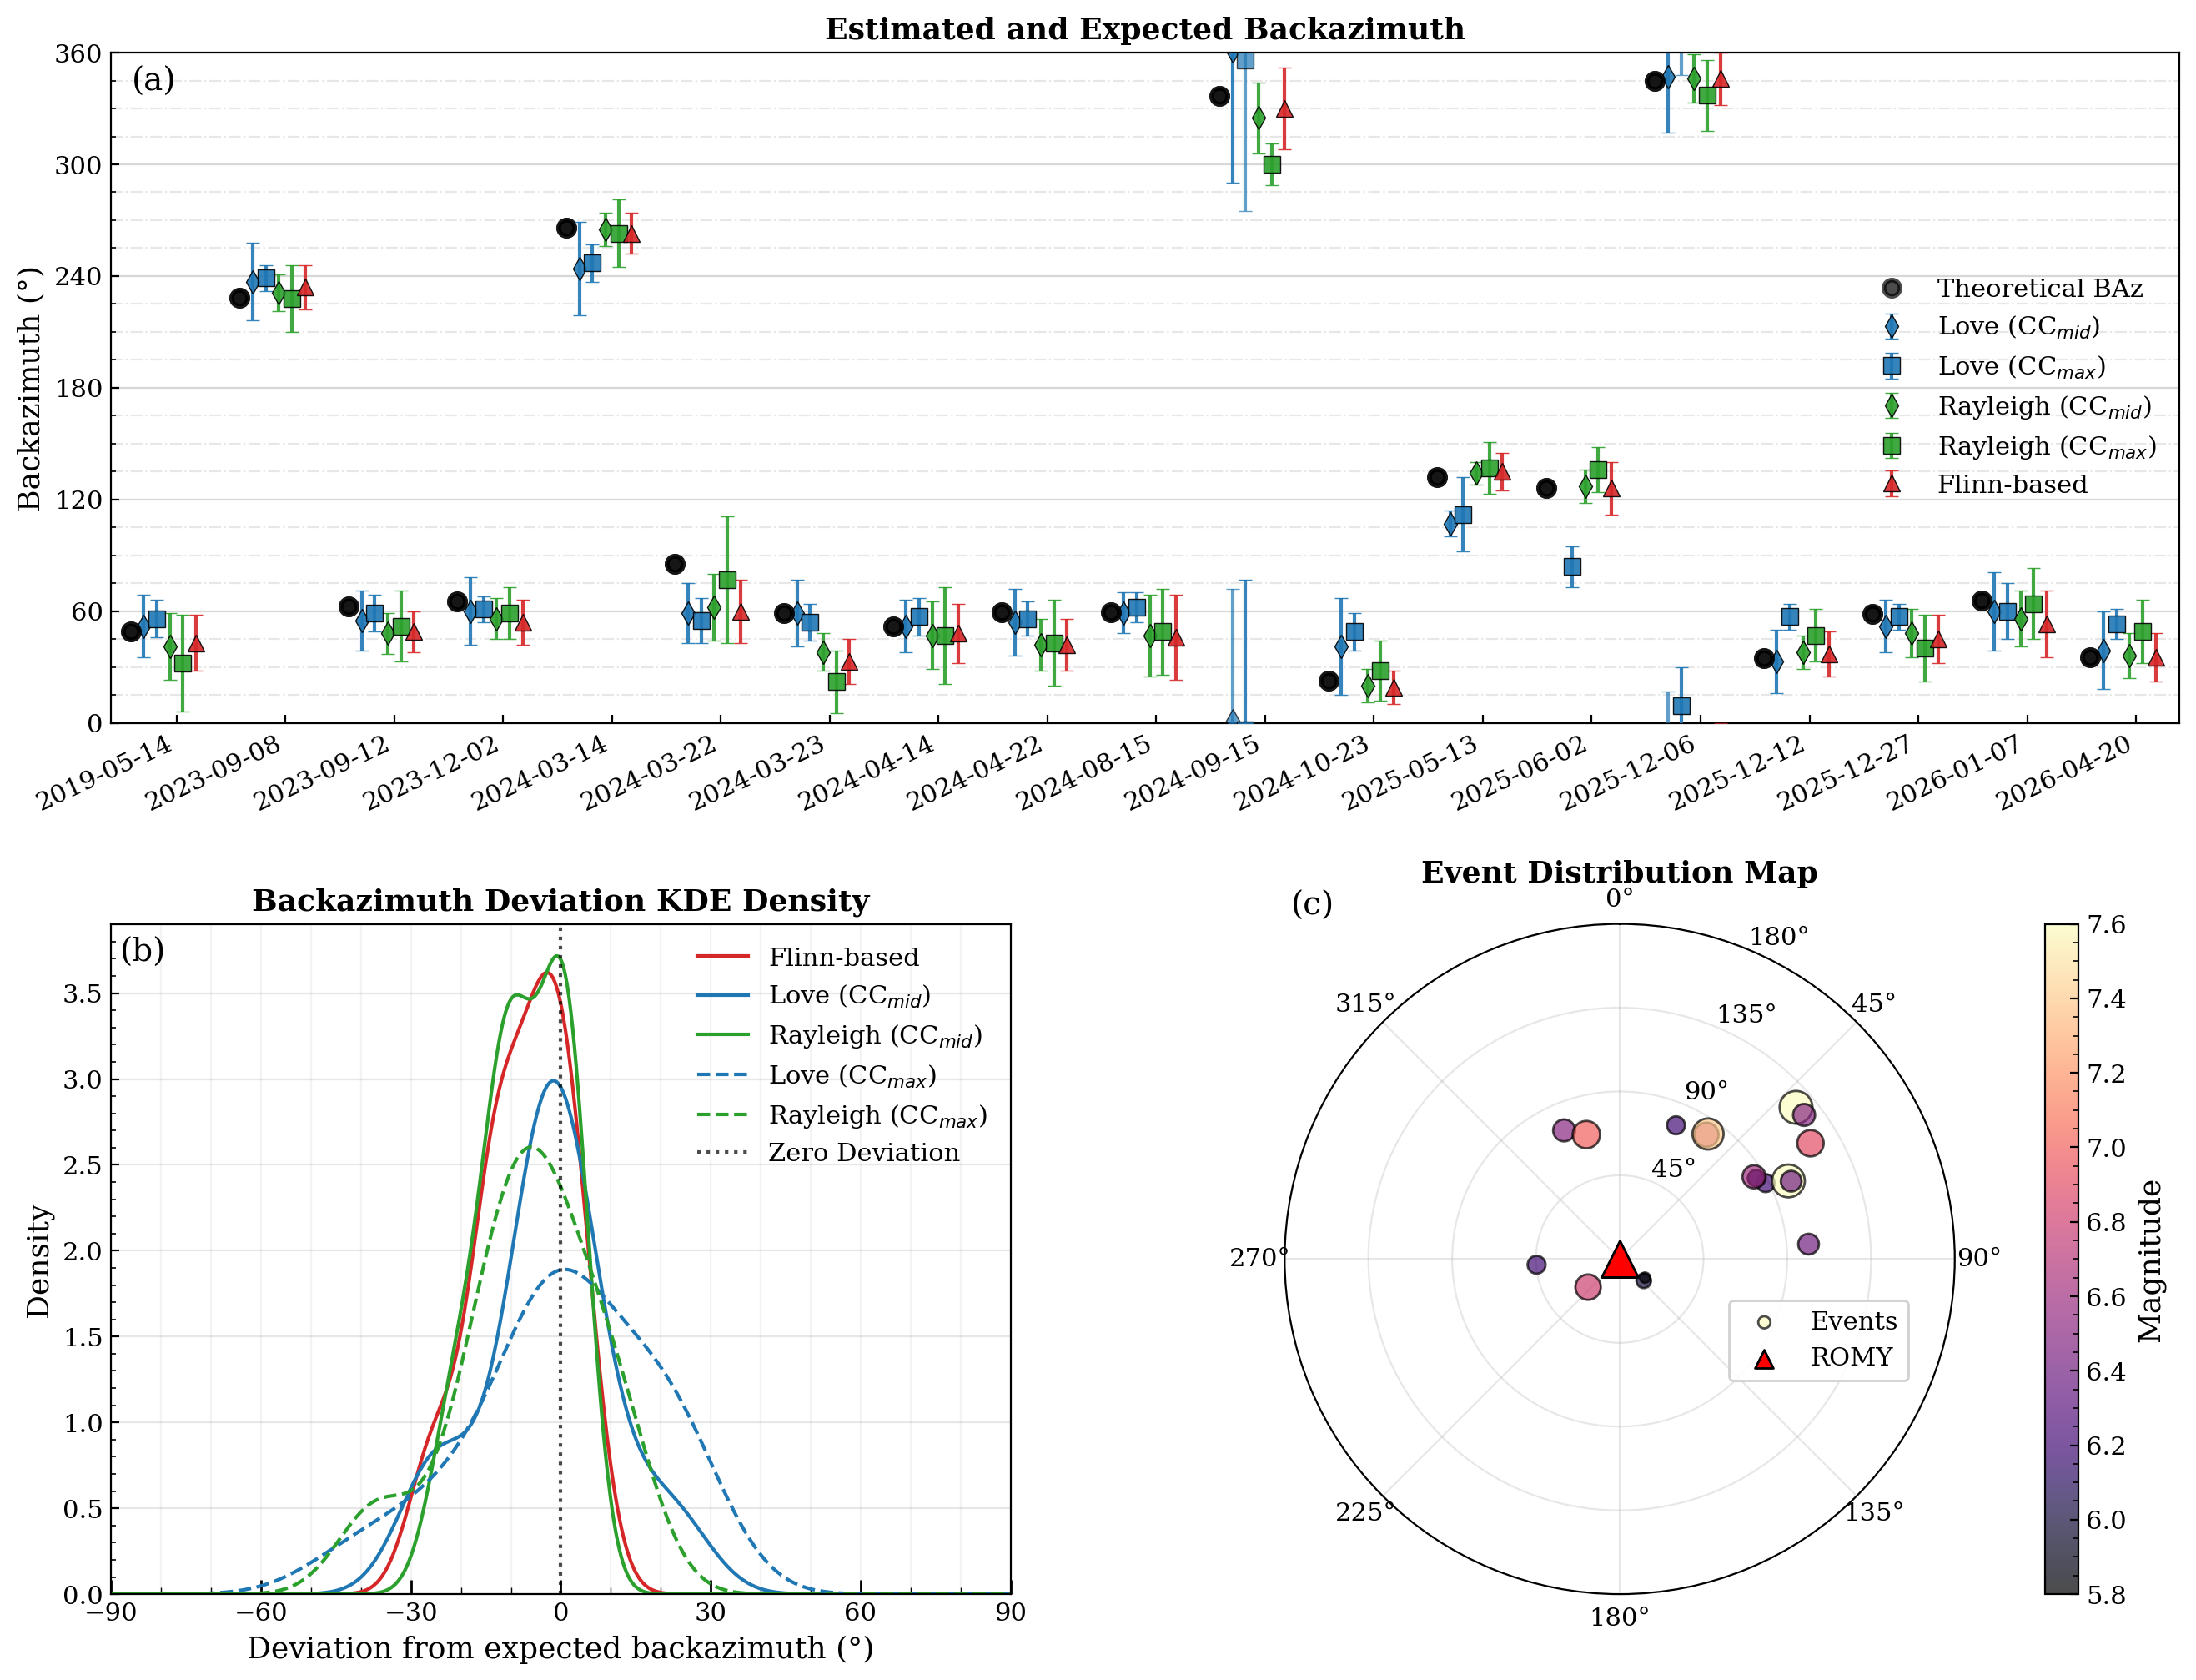

Saved: ./output/figures/backazimuth_results_summary.png


In [18]:
## Combined Plot: Backazimuth Comparison, KDE Density, and Polar Map

# Station coordinates (ROMY)
station_lat = 48.162941
station_lon = 11.275476

# Create figure with subplots: 2 rows, 2 columns
# Top row spans 2 columns, bottom row has 2 columns
fig = plt.figure(figsize=(16, 12))
gs = fig.add_gridspec(2, 2, hspace=0.3, wspace=0.3, 
                      height_ratios=[1, 1], width_ratios=[1, 1])

# ===== SUBPLOT 1: Backazimuth Comparison (top row, spans 2 columns) =====
ax1 = fig.add_subplot(gs[0, :])

# Get unique events
events = df_baz['event_date'].unique()
x_base = np.arange(len(events))
width = 0.12

# Colors and markers for different wave types and methods
colors = {
    ('love', 'mid'): 'tab:blue',
    ('love', 'max'): 'tab:blue',
    ('rayleigh', 'mid'): 'tab:green',
    ('rayleigh', 'max'): 'tab:green',
    ('tangent', 'mid'): 'tab:red',
    ('tangent', 'max'): 'tab:red',
}

markers = {
    ('love', 'mid'): 'd',
    ('love', 'max'): 's',
    ('rayleigh', 'mid'): 'd',
    ('rayleigh', 'max'): 's',
    ('tangent', 'mid'): '^',
    ('tangent', 'max'): 'v',
}

labels = {
    ('love', 'mid'): r'Love (CC$_{mid}$)',
    ('love', 'max'): r'Love (CC$_{max}$)',
    ('rayleigh', 'mid'): r'Rayleigh (CC$_{mid}$)',
    ('rayleigh', 'max'): r'Rayleigh (CC$_{max}$)',
    ('tangent', 'mid'): r'Flinn-based',
    ('tangent', 'max'): r'Flinn-based',
}

# Get theoretical values
theoretical = []
for event in events:
    theo_val = df_baz[df_baz['event_date'] == event]['backazimuth_theoretical'].iloc[0]
    theoretical.append(theo_val)
theoretical = np.array(theoretical)

# Plot theoretical values (leftmost position)
x_theoretical = x_base - width * 3.5
ax1.errorbar(x_theoretical, theoretical, fmt='o', color='black', markersize=7, 
            label='Theoretical BAz', linewidth=1.5, zorder=10, markeredgewidth=2, alpha=0.7)
ax1.errorbar(x_theoretical, theoretical % 360, fmt='o', color='black', markersize=7, 
            linewidth=1.5, zorder=10, markeredgewidth=2, alpha=0.7)
# ax1.errorbar(x_theoretical, theoretical, fmt='+', color='w', markersize=8, 
#             linewidth=0.5, zorder=10, markeredgewidth=1, alpha=0.9)

# Plot each combination
offset = -2.5
for wave_type in ['love', 'rayleigh', 'tangent']:
    # For tangent, only plot mid method
    methods_to_plot = ['mid', 'max'] if wave_type != 'tangent' else ['mid']
    
    for cc_method in methods_to_plot:
        df_subset = df_baz[(df_baz['wave_type'] == wave_type) & 
                           (df_baz['cc_method'] == cc_method)].copy()
        
        if len(df_subset) > 0:
            x_pos = []
            est_vals = []
            unc_vals = []
            
            for i, event in enumerate(events):
                event_data = df_subset[df_subset['event_date'] == event]
                if len(event_data) > 0:
                    x_pos.append(i + offset * width)
                    est_vals.append(event_data['backazimuth_estimate'].iloc[0])
                    unc_vals.append(event_data['backazimuth_uncertainty'].iloc[0])
            
            if len(x_pos) > 0:
                x_pos = np.array(x_pos)
                est_vals = np.array(est_vals)
                unc_vals = np.array(unc_vals)
                
                key = (wave_type, cc_method)
                ax1.errorbar(x_pos, est_vals, yerr=unc_vals, 
                           fmt=markers[key], color=colors[key], 
                           markersize=7, capsize=3, capthick=1.5, alpha=0.9,
                           label=labels[key], linewidth=1.5, zorder=5, 
                           markeredgecolor='k', markeredgewidth=0.5)
                ax1.errorbar(x_pos, est_vals + 360, yerr=unc_vals, 
                           fmt=markers[key], color=colors[key], 
                           markersize=7, capsize=3, capthick=1.5, alpha=0.7,
                           linewidth=1.5, zorder=5, markeredgecolor='k', markeredgewidth=0.5)
                ax1.errorbar(x_pos, est_vals - 360, yerr=unc_vals, 
                           fmt=markers[key], color=colors[key], 
                           markersize=7, capsize=3, capthick=1.5, alpha=0.7,
                           linewidth=1.5, zorder=5, markeredgecolor='k', markeredgewidth=0.5)
        
        offset += 1

ax1.set_yticks(np.arange(0, 420, 60))
ax1.tick_params(axis='both', which='major', labelsize=10)
ax1.set_ylabel('Backazimuth (°)', fontsize=13)
ax1.set_title('Estimated and Expected Backazimuth', fontsize=13, fontweight='bold')
ax1.set_xticks(x_base)
xlables = [str(l)[:4]+"-"+str(l)[4:6]+"-"+str(l)[6:] for l in events]
ax1.set_xticklabels(xlables, rotation=25, ha='right', fontsize=11)
ax1.set_ylim(0, 360)
ax1.set_xlim(-0.6, len(events)-0.6)
ax1.legend(fontsize=11, loc=7, ncol=1, framealpha=0.9)
ax1.get_yaxis().set_minor_locator(mpl.ticker.AutoMinorLocator())
ax1.grid(which='major', alpha=0.5, axis='y', zorder=0)
ax1.grid(which='minor', alpha=0.3, axis='y', zorder=0, ls="-.")

# turn off minor x ticks 
ax1.tick_params(axis='x', which='minor', length=0)

# Add subplot label (a)
ax1.text(0.01, 0.98, '(a)', transform=ax1.transAxes, fontsize=14,
         verticalalignment='top')

# ===== SUBPLOT 2: KDE Density Plot (bottom left) =====
ax2 = fig.add_subplot(gs[1, 0])

# Function to calculate circular deviation (wrapped to [-180, 180])
def circular_deviation(estimated, theoretical):
    """Calculate deviation between estimated and theoretical, wrapped to [-180, 180] degrees."""
    diff = estimated - theoretical
    # Wrap to [-180, 180]
    diff = np.where(diff > 180, diff - 360, diff)
    diff = np.where(diff < -180, diff + 360, diff)
    return diff

# Calculate deviations for all methods
deviations = {}

for wave_type in ['love', 'rayleigh', 'tangent']:
    for cc_method in ['mid', 'max']:
        df_subset = df_baz[(df_baz['wave_type'] == wave_type) & 
                          (df_baz['cc_method'] == cc_method)].copy()
        
        if len(df_subset) > 0:
            # Filter out NaN values
            valid = df_subset.dropna(subset=['backazimuth_estimate', 'backazimuth_theoretical'])
            if len(valid) > 0:
                key = f'{wave_type.capitalize()} {cc_method.capitalize()}'
                deviations[key] = circular_deviation(
                    valid['backazimuth_estimate'].values,
                    valid['backazimuth_theoretical'].values
                )

# Choose which family to compare ('velocity' or 'acceleration')
# For ROMY, we use 'love' as the primary wave type
family = 'love'  # We'll plot Love and Rayleigh methods

# Create fine grid for KDE evaluation
x_kde = np.linspace(-180, 180, 1000)

# Colors for methods
colors_kde = {
    'Love Mid': 'tab:blue',
    'Love Max': 'tab:blue',
    'Rayleigh Mid': 'tab:green',
    'Rayleigh Max': 'tab:green',
    'Tangent Mid': 'tab:red',
}

# Pretty labels for legend
labels_kde = {
    'Love Mid': r'Love (CC$_{mid}$)',
    'Love Max': r'Love (CC$_{max}$)',
    'Rayleigh Mid': r'Rayleigh (CC$_{mid}$)',
    'Rayleigh Max': r'Rayleigh (CC$_{max}$)',
    'Tangent Mid': r'Flinn-based',
}

# Collect methods to plot
methods_to_plot = []
if 'Tangent Mid' in deviations:
    methods_to_plot.append('Tangent Mid')

# Add max and midpoint for Love and Rayleigh
# methods = ['Love Max', 'Love Mid', 'Rayleigh Max', 'Rayleigh Mid']
methods = ['Love Mid', 'Rayleigh Mid', 'Love Max', 'Rayleigh Max']

for method in methods:
    if method in deviations:
        methods_to_plot.append(method)

# Plot KDE density for each method
for method in methods_to_plot:
    if method in deviations and len(deviations[method]) > 1:
        data = deviations[method]
        
        # Calculate KDE (returns probability density function)
        kde = stats.gaussian_kde(data)
        kde_values = kde(x_kde)
        
        # Scale to match histogram counts: PDF * n_samples * bin_width
        bin_width_hist = 5.0
        kde_values = kde_values * len(data) * bin_width_hist
        
        if "Max" in method:
            ls = '--'
        else:
            ls = '-'

        ax2.plot(
            x_kde,
            kde_values,
            linewidth=1.5,
            alpha=1,
            linestyle=ls,
            label=labels_kde.get(method, method),
            color=colors_kde.get(method, 'gray'),
        )
        
        # Fill under the curve with transparency
        # ax2.fill_between(
        #     x_kde,
        #     kde_values,
        #     alpha=0.2,
        #     color=colors_kde.get(method, 'gray'),
        # )

# Reference line at zero deviation
ax2.axvline(x=0, color='black', linestyle=':', linewidth=1.5, alpha=0.7, label='Zero Deviation')

ax2.set_xlabel('Deviation from expected backazimuth (°)', fontsize=13)
ax2.set_ylabel('Density', fontsize=13)
ax2.set_title('Backazimuth Deviation KDE Density', fontsize=13, fontweight='bold')
ax2.set_xlim(-90, 90)
ax2.set_ylim(bottom=0)

# Add minor ticks for x-axis
ax2.set_xticks(np.arange(-90, 91, 10), minor=True)
ax2.set_xticks(np.arange(-90, 91, 30), minor=False)
ax2.tick_params(axis='x', which='minor', length=3, width=0.5)
ax2.tick_params(axis='x', which='major', length=6, width=1)

ax2.legend(fontsize=11)
ax2.grid(True, alpha=0.3, axis='y', which='major')
ax2.grid(True, alpha=0.15, axis='x', which='both', linestyle='-')

# Add subplot label (b)
ax2.text(0.01, 0.98, '(b)', transform=ax2.transAxes, fontsize=14,
         verticalalignment='top')

# ===== SUBPLOT 3: Polar Map (bottom right) =====
ax3 = fig.add_subplot(gs[1, 1], projection='polar')

# Make a discrete color map
cmap = plt.cm.magma

# Get event data with valid theoretical backazimuth and distance
valid_events = df_baz.dropna(subset=['backazimuth_theoretical', 'distance_km', 'magnitude'])

# Get unique events with their data
unique_events = valid_events.groupby('event_date').first().reset_index()

if len(unique_events) > 0:
    # Convert distance from km to degrees
    epicentral_distance_degrees = unique_events['distance_km'].values / 6371 * 180 / np.pi
    
    # Set radial limits (distance in degrees) - need to set early for continent plotting
    max_distance = 180
    ax3.set_ylim(0, max_distance)
    
    # Set theta zero location to North (0°) and clockwise direction
    ax3.set_theta_zero_location('N')
    ax3.set_theta_direction(-1)
        
    # Convert backazimuth to radians (for polar plot)
    baz_rad = np.deg2rad(unique_events['backazimuth_theoretical'].values)
    distances = epicentral_distance_degrees
    magnitudes = unique_events['magnitude'].values
    
    # Scale marker size by magnitude (min size 20, max size 200)
    min_mag = magnitudes.min()
    max_mag = magnitudes.max()
    if max_mag > min_mag:
        marker_sizes = 20 + (magnitudes - min_mag) / (max_mag - min_mag) * 180
    else:
        marker_sizes = np.full_like(magnitudes, 100)
    
    # Create discrete colorbar levels (0.2 steps)
    mag_min_rounded = np.floor(min_mag * 5) / 5  # Round down to nearest 0.2
    mag_max_rounded = np.ceil(max_mag * 5) / 5    # Round up to nearest 0.2
    mag_levels = np.arange(mag_min_rounded, mag_max_rounded + 0.2, 0.2)
    
    # Plot events with discrete colors
    scatter = ax3.scatter(baz_rad, distances, c=magnitudes, s=marker_sizes, 
                         cmap=cmap, alpha=0.7, edgecolors='black', linewidths=1,
                         zorder=5, label='Events', vmin=mag_levels[0], vmax=mag_levels[-1])
    
    # Add discrete colorbar
    cbar = plt.colorbar(scatter, ax=ax3, pad=0.1, ticks=mag_levels)
    cbar.set_label('Magnitude', fontsize=13)
    cbar.set_ticklabels([f'{m:.1f}' for m in mag_levels])
    
    # Plot station at center (distance = 0)
    ax3.scatter(0, 0, marker='^', s=250, color='red',
               edgecolors='black', linewidths=1, zorder=2, label='ROMY')
    
    # Customize radial axis
    ax3.set_title('Event Distribution Map', fontsize=13, fontweight='bold', pad=2)
    
    # Set radial axis labels with unit degrees
    ax3.set_yticklabels([f'{int(d)}°' for d in ax3.get_yticks()], fontsize=13)

    # Add grid
    ax3.grid(True, alpha=0.3)
    
    # Add legend
    ax3.legend(loc='lower right', fontsize=11, frameon=True, framealpha=0.9, markerscale=0.5, bbox_to_anchor=(0.95, 0.3))
    
    # Add distance circles
    ax3.set_yticks(np.linspace(0, max_distance, 5))

    ylbls = [f'{int(d)}°' for d in np.linspace(0, max_distance, 5)]
    ylbls[0] = ''
    ax3.set_yticklabels(ylbls, fontsize=11)
    
    # Add subplot label (c)
    ax3.text(0.01, 1.05, '(c)', transform=ax3.transAxes, fontsize=14,
             verticalalignment='top', zorder=15)

ax1.tick_params(axis='both', which='major', labelsize=11)
ax2.tick_params(axis='both', which='major', labelsize=11)
ax3.tick_params(axis='both', which='major', labelsize=11)

plt.tight_layout()
plt.show()

output_file = os.path.join(output_dir, 'backazimuth_results_summary.png')
fig.savefig(output_file, bbox_inches='tight', dpi=150)
print(f"Saved: {output_file}")
